### Task 1: Load and Preprocess the Fashion MNIST Dataset

In [1]:
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader
from torchvision import datasets, transforms
import matplotlib.pyplot as plt
import numpy as np

# Set device
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Using device: {device}")

# Define transforms
transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.5,), (0.5,))
])

# Download and load training and test datasets
train_dataset = datasets.FashionMNIST(root='./data', train=True, download=True, transform=transform)
test_dataset = datasets.FashionMNIST(root='./data', train=False, download=True, transform=transform)

# Define data loaders
batch_size = 64
train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=batch_size, shuffle=False)

# Classes
classes = ['T-shirt/top', 'Trouser', 'Pullover', 'Dress', 'Coat', 'Sandal', 'Shirt', 'Sneaker', 'Bag', 'Ankle boot']

Using device: cuda


100%|██████████| 26.4M/26.4M [00:02<00:00, 11.6MB/s]
100%|██████████| 29.5k/29.5k [00:00<00:00, 168kB/s]
100%|██████████| 4.42M/4.42M [00:01<00:00, 3.15MB/s]
100%|██████████| 5.15k/5.15k [00:00<00:00, 25.8MB/s]


### Task 2: Build the PyTorch Model
We will define a simple Convolutional Neural Network (CNN) suitable for Fashion MNIST.

In [2]:
class FashionCNN(nn.Module):
    def __init__(self):
        super(FashionCNN, self).__init__()
        self.features = nn.Sequential(
            nn.Conv2d(1, 16, kernel_size=3, padding=1),
            nn.BatchNorm2d(16),
            nn.ReLU(),
            nn.MaxPool2d(2, 2),
            nn.Conv2d(16, 32, kernel_size=3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(),
            nn.MaxPool2d(2, 2)
        )
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(32 * 7 * 7, 128),
            nn.ReLU(),
            nn.Dropout(0.25),
            nn.Linear(128, 10)
        )

    def forward(self, x):
        x = self.features(x)
        x = self.classifier(x)
        return x

### Task 3 & 4: Train and Evaluate Model Helper Functions

In [3]:
def train_model(optimizer_name, lr=0.001, epochs=10):
    model = FashionCNN().to(device)
    criterion = nn.CrossEntropyLoss()

    if optimizer_name == 'SGD':
        optimizer = optim.SGD(model.parameters(), lr=lr, momentum=0.9)
    elif optimizer_name == 'Adam':
        optimizer = optim.Adam(model.parameters(), lr=lr)
    else:
        raise ValueError("Optimizer must be SGD or Adam")

    train_losses = []
    train_accuracies = []

    for epoch in range(epochs):
        model.train()
        running_loss = 0.0
        correct = 0
        total = 0

        for images, labels in train_loader:
            images, labels = images.to(device), labels.to(device)

            optimizer.zero_grad()
            outputs = model(images)
            loss = criterion(outputs, labels)
            loss.backward()
            optimizer.step()

            running_loss += loss.item() * images.size(0)
            _, predicted = torch.max(outputs.data, 1)
            total += labels.size(0)
            correct += (predicted == labels).sum().item()

        epoch_loss = running_loss / len(train_loader.dataset)
        epoch_acc = 100 * correct / total
        train_losses.append(epoch_loss)
        train_accuracies.append(epoch_acc)
        print(f"[{optimizer_name}] Epoch {epoch+1}/{epochs} - Loss: {epoch_loss:.4f} - Acc: {epoch_acc:.2f}%")

    return model, train_losses, train_accuracies

def evaluate_model(model):
    model.eval()
    correct = 0
    total = 0
    with torch.no_grad():
        for images, labels in test_loader:
            images, labels = images.to(device), labels.to(device)
            outputs = model(images)
            _, predicted = torch.max(outputs.data, 1)
            total += labels.size(0)
            correct += (predicted == labels).sum().item()
    return 100 * correct / total

### Execute Training for SGD and Adam

In [4]:
epochs = 10
print("Training model with SGD Optimizer...")
sgd_model, sgd_losses, sgd_accs = train_model('SGD', lr=0.01, epochs=epochs)

print("\nTraining model with Adam Optimizer...")
adam_model, adam_losses, adam_accs = train_model('Adam', lr=0.001, epochs=epochs)

sgd_test_acc = evaluate_model(sgd_model)
adam_test_acc = evaluate_model(adam_model)

print(f"\nSGD Test Accuracy: {sgd_test_acc:.2f}%")
print(f"Adam Test Accuracy: {adam_test_acc:.2f}%")

Training model with SGD Optimizer...
[SGD] Epoch 1/10 - Loss: 0.4566 - Acc: 83.38%
[SGD] Epoch 2/10 - Loss: 0.3136 - Acc: 88.62%
[SGD] Epoch 3/10 - Loss: 0.2718 - Acc: 89.96%
[SGD] Epoch 4/10 - Loss: 0.2491 - Acc: 90.78%
[SGD] Epoch 5/10 - Loss: 0.2230 - Acc: 91.69%
[SGD] Epoch 6/10 - Loss: 0.2079 - Acc: 92.31%
[SGD] Epoch 7/10 - Loss: 0.1952 - Acc: 92.71%
[SGD] Epoch 8/10 - Loss: 0.1826 - Acc: 93.17%
[SGD] Epoch 9/10 - Loss: 0.1732 - Acc: 93.47%
[SGD] Epoch 10/10 - Loss: 0.1613 - Acc: 93.91%

Training model with Adam Optimizer...
[Adam] Epoch 1/10 - Loss: 0.4237 - Acc: 84.82%
[Adam] Epoch 2/10 - Loss: 0.2951 - Acc: 89.23%
[Adam] Epoch 3/10 - Loss: 0.2568 - Acc: 90.53%
[Adam] Epoch 4/10 - Loss: 0.2313 - Acc: 91.39%
[Adam] Epoch 5/10 - Loss: 0.2135 - Acc: 92.14%
[Adam] Epoch 6/10 - Loss: 0.1973 - Acc: 92.70%
[Adam] Epoch 7/10 - Loss: 0.1825 - Acc: 93.06%
[Adam] Epoch 8/10 - Loss: 0.1680 - Acc: 93.69%
[Adam] Epoch 9/10 - Loss: 0.1579 - Acc: 94.03%
[Adam] Epoch 10/10 - Loss: 0.1479 - Acc:

### Task 5: Visualize Results

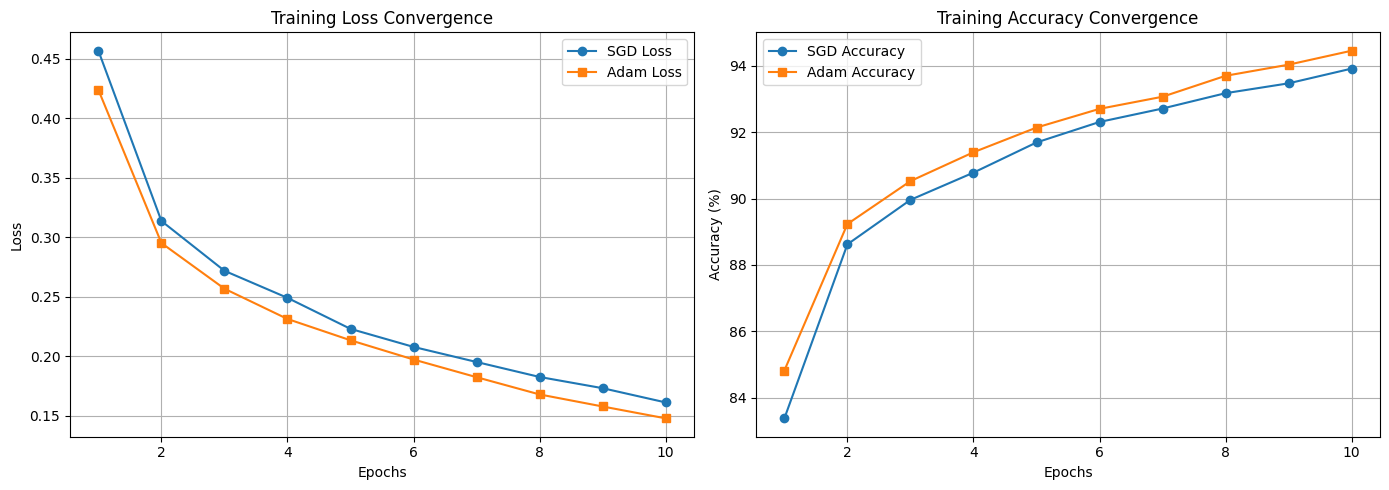

In [5]:
epochs_range = range(1, epochs + 1)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Loss plot
ax1.plot(epochs_range, sgd_losses, label='SGD Loss', marker='o')
ax1.plot(epochs_range, adam_losses, label='Adam Loss', marker='s')
ax1.set_title('Training Loss Convergence')
ax1.set_xlabel('Epochs')
ax1.set_ylabel('Loss')
ax1.legend()
ax1.grid(True)

# Accuracy plot
ax2.plot(epochs_range, sgd_accs, label='SGD Accuracy', marker='o')
ax2.plot(epochs_range, adam_accs, label='Adam Accuracy', marker='s')
ax2.set_title('Training Accuracy Convergence')
ax2.set_xlabel('Epochs')
ax2.set_ylabel('Accuracy (%)')
ax2.legend()
ax2.grid(True)

plt.tight_layout()
plt.show()

### Task 6: Brief Conclusion

* **Adam Optimizer**: Typically converges significantly faster in the initial epochs due to its adaptive learning rate system. It is generally less sensitive to hyperparameter choices.
* **SGD (with Momentum)**: Converges more steadily and slowly, but often reaches a highly competitive (and sometimes slightly better generalizing) final model accuracy if given sufficient epochs and fine-tuned learning rates.
* **Observations**: From the plots, we can observe which optimizer minimized the loss quicker and how their accuracies developed side-by-side during the 10 training epochs.